# Idea 2: buy put options instead of closing out?
When turbulence is above the threshold, the paper **sells everything** and buys nothing until it calms down. That avoids crashes but costs fees and misses rebounds.

**Alternative (`put`):** keep the stocks and buy **1-month at-the-money SPY puts** worth as much as the stock positions, as insurance. They're priced with Black-Scholes, using **VIX** as volatility and the **T-bill rate**, plus 1% trading cost. Puts are held to expiry and rolled over while turbulence stays high.

We compare the three crash rules on exactly the same trained agents (baseline, 5 seeds), so the rule is the only difference:
- `none`: ignore turbulence
- `sell`: the paper
- `put`: insurance

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from backtest import STRATEGIES, pretty, sharpe, summary

bt = pd.read_parquet('results/backtest.parquet')
baselines = pd.read_parquet('results/baselines.parquet')
ens = bt[(bt.variant == 'baseline') & (bt.strategy == 'ensemble')]

## Full period (Oct 2000 – Dec 2025), ensemble strategy

In [2]:
pretty(summary(ens, baselines, by='rule').loc[['none', 'sell', 'put', 'DJIA']])

,Cumulative return,Annual return,Annual volatility,Sharpe (rf = 0),Sharpe (excess),Max drawdown,Sharpe std over seeds
none,649.5%,8.2%,19.7%,0.50,0.41,-56.5%,0.06
sell,304.1%,5.6%,15.9%,0.43,0.31,-41.5%,0.05
put,422.3%,6.7%,17.0%,0.46,0.36,-50.2%,0.06
DJIA,716.7%,8.7%,18.3%,0.55,0.45,-51.8%,


## How often is the market "turbulent"?

2.2% of days are turbulent, in 103 separate episodes


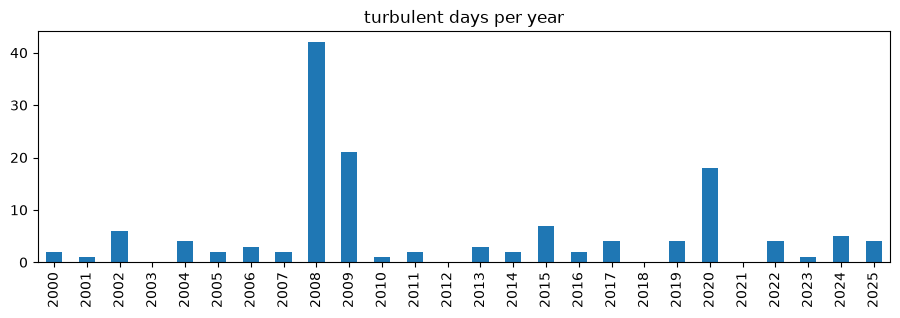

In [3]:
flags = ens[(ens.rule == 'sell') & (ens.seed == 0)].set_index('date').turbulent
episodes = (flags & ~flags.shift(fill_value=False)).sum()
print(f'{flags.mean():.1%} of days are turbulent, in {episodes} separate episodes')
flags.groupby(flags.index.year).sum().plot.bar(figsize=(11, 3), title='turbulent days per year', xlabel='');

## Crashes and rebounds

In [4]:
windows = {
    'Dot-com crash (Oct 2000 – Oct 2002)': ('2000-10-01', '2002-10-09'),
    'Financial crisis (Sep 2008 – Mar 2009)': ('2008-09-01', '2009-03-09'),
    'Rebound (Mar 2009 – Dec 2009)': ('2009-03-10', '2009-12-31'),
    'COVID crash (Feb 20 – Mar 23, 2020)': ('2020-02-20', '2020-03-23'),
    'COVID rebound (Mar 24 – Aug 2020)': ('2020-03-24', '2020-08-31'),
    '2022 bear market (Jan – Oct 2022)': ('2022-01-03', '2022-10-12'),
}
rows = {}
for name, (a, b) in windows.items():
    w = ens[(ens.date >= a) & (ens.date <= b)]
    row = w.groupby(['rule', 'seed']).ret.apply(lambda r: (1 + r).prod() - 1).groupby('rule').mean()
    row['DJIA'] = (1 + baselines.DJIA.loc[a:b]).prod() - 1
    rows[name] = row
pd.DataFrame(rows).T[['none', 'sell', 'put', 'DJIA']].style.format('{:.1%}')

rule,none,sell,put,DJIA
Dot-com crash (Oct 2000 – Oct 2002),-31.7%,-33.6%,-32.4%,-29.0%
Financial crisis (Sep 2008 – Mar 2009),-47.3%,-27.2%,-37.4%,-42.2%
Rebound (Mar 2009 – Dec 2009),80.9%,35.8%,53.2%,63.1%
"COVID crash (Feb 20 – Mar 23, 2020)",-31.7%,-16.1%,-16.0%,-36.5%
COVID rebound (Mar 24 – Aug 2020),45.1%,12.2%,13.4%,55.4%
2022 bear market (Jan – Oct 2022),-16.9%,-20.3%,-14.0%,-18.3%


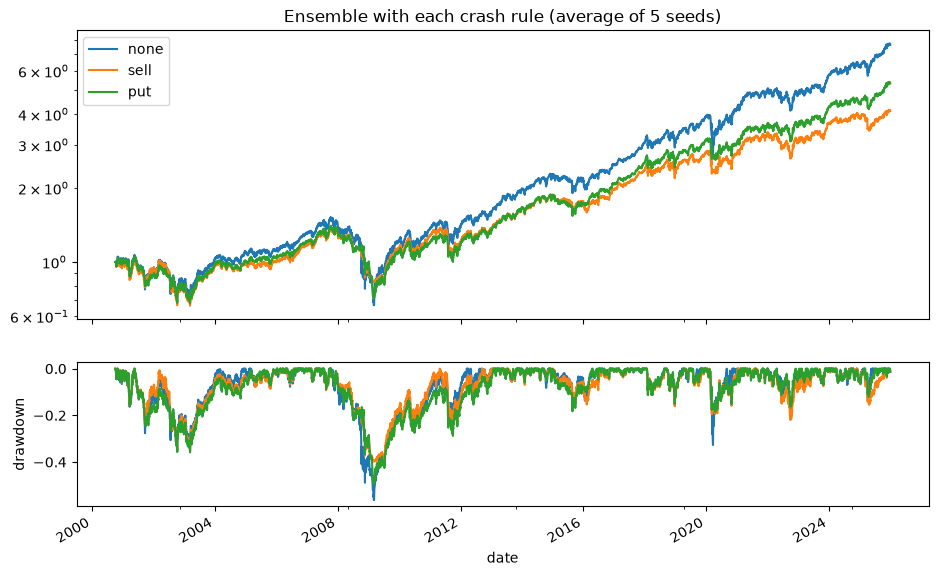

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, height_ratios=[2, 1])
for rule in ['none', 'sell', 'put']:
    v = (1 + ens[ens.rule == rule].groupby('date').ret.mean()).cumprod()
    v.plot(ax=axes[0], label=rule)
    (v / v.cummax() - 1).plot(ax=axes[1], label=rule)
axes[0].set_yscale('log')
axes[0].set_title('Ensemble with each crash rule (average of 5 seeds)')
axes[0].legend()
axes[1].set_ylabel('drawdown');

## Is it the same for every agent and for FTA?
Sharpe ratio (average of 5 seeds) for each agent, crash rule and variant. If `put` beats `sell` everywhere, the result doesn't depend on which agent is trading.

In [6]:
sh = bt.groupby(['variant', 'strategy', 'rule', 'seed']).ret.apply(sharpe).groupby(['variant', 'strategy', 'rule']).mean()
sh.unstack('rule')[['none', 'sell', 'put']].round(2)

rule               none  sell   put
variant  strategy                  
baseline a2c       0.50  0.41  0.47
         ddpg      0.45  0.41  0.40
         ensemble  0.50  0.43  0.46
         ppo       0.55  0.52  0.53
fta      a2c       0.48  0.45  0.45
         ddpg      0.37  0.31  0.34
         ensemble  0.48  0.38  0.43
         ppo       0.56  0.55  0.53

In [7]:
per_seed = ens.groupby(['rule', 'seed']).ret.apply(sharpe).unstack('rule')[['none', 'sell', 'put']]
print('ensemble: put beats sell in', (per_seed.put > per_seed.sell).sum(), 'of 5 seeds')
runs = bt.groupby(['variant', 'strategy', 'rule', 'seed']).ret.apply(sharpe).unstack('rule')
print(f'all {len(runs)} runs (2 variants x 4 strategies x 5 seeds): put beats sell in {(runs.put > runs.sell).sum()}, '
      f'none beats put in {(runs.none > runs.put).sum()}, none beats sell in {(runs.none > runs.sell).sum()}')
per_seed.round(2)

ensemble: put beats sell in 5 of 5 seeds
all 40 runs (2 variants x 4 strategies x 5 seeds): put beats sell in 27, none beats put in 40, none beats sell in 31


rule,none,sell,put
seed,,,
0,0.47,0.45,0.46
1,0.44,0.34,0.37
2,0.53,0.47,0.49
3,0.48,0.41,0.45
4,0.58,0.46,0.55


## Conclusion
**Buying puts beats closing out on return and Sharpe ratio. Closing out protects better in long crashes. Neither beats ignoring turbulence.**
- **Puts vs. selling:** the ensemble's Sharpe ratio is 0.46 with puts against 0.43 when selling. Puts win in all 5 seeds and in 27 of the 40 runs. Annual return is 6.7% against 5.6%.
- **Selling limits losses best:** max drawdown −42% against −50% (puts) and −57% (no rule). In the 2008 crisis, selling lost 27%, puts 37% and no rule 47%.
- **Puts keep the upside:** in the 2009 rebound, puts gained 53% against 36% for selling. In the short COVID crash both cut the loss in half (−16% against −32%). In the 2022 bear market puts did best (−14%).
- **Insurance is expensive exactly when this rule buys it.** The rule buys after turbulence spikes, when VIX is already high: on 16 Mar 2020, at VIX 83, a 1-month at-the-money put cost 9.5% of the position. That's why both rules lag the 2020 rebound, and why ignoring turbulence has the best Sharpe ratio (0.50). It beats puts in all 40 runs and selling in 31.

**In short:** if the goal is the paper's, cutting crash losses, closing out works best. For risk-adjusted return, puts are the better of the two crash rules. The paper's threshold fires on 2% of days (103 separate episodes), too often for either kind of protection to pay for itself over 25 years.